# Model comparison: label distributions on English Nemotron-CC

> **Superseded (2 October 2026):** use [`model_selection.ipynb`](model_selection.ipynb), which
> compares all five candidate models on both label types and all six languages and
> includes every analysis in this notebook. This notebook reproduces the report from
> the original English runs (24 labels, 10,000 documents, random prompt order), which
> have since been replaced; it stops with a message unless those files are restored to
> the paths in `RUNS`.

Reproduces **section 3, "Model comparison"**, of
[`docs/label_distribution_pipeline.md`](../docs/label_distribution_pipeline.md).

**Question:** how do candidate models differ in the distributions they produce, and
which gives the most informative soft labels?

**Design:** three models labelled the same English Nemotron-CC documents with the
same prompt and the same seed, and therefore the same label order per document, so
every difference comes from the model. As a reference point, the notebook also
measures WebOrganizer's Llama-3.1-405B annotations; those are on WebOrganizer's own
documents, so they're comparable in shape only, not document by document.

**Sections:** 1. load · 2. confidence · 3. what's left after the top label ·
4. agreement between models · 5. Qwen vs Gemma disagreements · 6. summary against the report.

**Running it:** on Roihu, `module load python-vllm/0.19.1` provides pandas,
matplotlib and JupyterLab. The first run downloads a sample of WebOrganizer's label
fields (no document text) through the Hugging Face dataset viewer API, which needs
internet access, and caches it in `data/weborganizer_samples/`.

**Common modifications** (all in the parameter cell):

- *Use all shared documents instead of the report's 2,048:* set `N_DOCS = None`.
- *Add a model:* add its output file to `RUNS`. It must be a run on the same
  documents with the same seed and prompt order, or the label-order check reports
  `False`. Section 5 compares Qwen and Gemma by name; change the names there to
  compare another pair.
- *Format labels:* point `RUNS` at format runs, `LABELS_PATH` at `formats.yaml`, and
  `WO_405B_DATASET` at `WebOrganizer/FormatAnnotations-Llama-3.1-405B-FP8`.
- *Runs with the added labels (`Other`, `Bad example`):* all runs in `RUNS` must use
  the same label set, either WebOrganizer's 24 labels or all 26.

## Setup

This cell imports everything the notebook needs and defines two small helpers.

- **Repository root:** the notebook works whether Jupyter was started in the
  repository root or in `notebooks/`, by locating the root from the current directory.
- **Shared code instead of reimplementing metrics:** loading, validation and metrics come
  from `scripts/data_analysis/distribution_metrics.py`, and WebOrganizer rows are
  converted with `reference_record` from `evaluate_distribution_reference.py`. The
  notebook therefore computes exactly what the evaluation scripts compute; if a metric
  changes there, it changes here too.
- **`weborganizer_samples.fetch_rows`** downloads and caches WebOrganizer's label fields.
- **Added labels:** our taxonomies add `Other` and `Bad example`, which WebOrganizer's
  data doesn't have. `weborganizer_label_subset` splits our label file into
  WebOrganizer's 24 labels and the added ones, and `restrict_to_labels` routes the
  added labels back for comparisons: their probability is removed and the rest is
  renormalized, as `evaluate_distribution_reference.py` does. The report's runs were
  made before the labels were added and have 24 labels; runs made since have 26.
- **Helpers:** `quantile` defines percentiles as the element at index `int(q * n)` of the
  sorted values, the definition used for the report; `top_prob` is the probability of a
  document's most likely label.

In [1]:
from __future__ import annotations

import math
import statistics
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "data_analysis"))

# The same loading and metrics as the evaluation scripts, so the numbers agree.
from distribution_metrics import (
    cohen_kappa,           # chance-corrected agreement between two sets of top labels
    entropy_bits,          # entropy of one distribution, in bits
    jensen_shannon_bits,   # divergence between two distributions, 0 (same) to 1 bit
    letter_bias,           # tests whether the shown letter predicts the chosen label
    probabilities,         # log-probabilities -> probabilities
    ranked_indices,        # label indices from most to least probable
    read_distribution_file,
    restrict_to_labels,    # drop labels and renormalize (routes added labels back)
    top_confusions,        # most frequent (reference, candidate) disagreements
    top_index,             # index of the most probable label
)
from evaluate_distribution_reference import load_label_names, reference_record, weborganizer_label_subset
from weborganizer_samples import fetch_rows

# Answer letters in the order they were shown; position 0 = "A". Runs with 24
# labels use A-X, runs with the added labels use A-Z.
LETTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"


def quantile(values, q):
    """Return the q-quantile as the element at index int(q * n) of the sorted values."""
    ordered = sorted(values)
    return ordered[min(len(ordered) - 1, int(q * len(ordered)))]


def top_prob(record):
    """Return the probability of the record's most likely label."""
    return math.exp(max(record.logprobs))

## Parameters

- `N_DOCS`: how many documents to use, from those labelled by every model. The
  default, 2,048, is the number the runs shared when the report was written, so the
  defaults reproduce the report exactly. `None` uses all shared documents.
- `RUNS`: the runs to compare, by display name.
- `LABELS_PATH`: our label file: WebOrganizer's labels in taxonomy order, followed by
  the added labels. Used to read the WebOrganizer reference sample.
- `CACHE_DIR`: where downloaded WebOrganizer rows are cached.
- `WO_405B_DATASET` and `WO_405B_OFFSETS`: the WebOrganizer-405B reference sample,
  100 rows at every 5,000th row as in the report.

In [2]:
# None uses every document shared by all runs.
N_DOCS = None

RUNS = {
    "Gemma-4-31B": ROOT / "results/distribution/gemma-4-31B-it-annotations/topic/english-parallel.jsonl",
    "Qwen3.8-27B": ROOT / "results/distribution/Qwen3.8-27B-annotations/topic/english-parallel.jsonl",
    "Llama-3.1-8B": ROOT / "results/distribution/Llama-3.1-8B-Instruct-annotations/topic/english-parallel.jsonl",
}
LABELS_PATH = ROOT / "scripts/data_processing/topics.yaml"
CACHE_DIR = ROOT / "data/weborganizer_samples"
# The train split has fewer than 80,000 rows, so the last offsets return nothing
# and the sample has 1,600 rows.
WO_405B_DATASET = "WebOrganizer/TopicAnnotations-Llama-3.1-405B-FP8"
WO_405B_OFFSETS = list(range(0, 100_000, 5_000))

## 1. Load the runs

Each run is read and validated with `read_distribution_file`. All runs must use the
same label set (WebOrganizer's 24 labels, or all 26 of ours). Only documents that
every model labelled are used, in the order of the first run, so all comparisons are
on the same documents. `runs[model][k]` is document `k` for each model.

The cell also checks that every model saw each document with the **same label
order**. That's expected (same seed, same random prompt order), and it means
differences between models can't come from label order.

In [3]:
missing = [str(path.relative_to(ROOT)) for path in RUNS.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        f"The original runs for this notebook are not available ({', '.join(missing)}). "
        "They were replaced by the current 2,000-document runs; use model_selection.ipynb, "
        "or restore the original files to the paths in RUNS."
    )
all_names, all_labels = load_label_names(LABELS_PATH)
# WebOrganizer's 24 labels, for reading the reference sample.
wo_label_names, wo_labels, _ = weborganizer_label_subset(all_names, all_labels)
loaded = {}
labels = None
for model, path in RUNS.items():
    run_labels, records = read_distribution_file(path)
    assert run_labels in (wo_labels, all_labels), f"{model}: labels match neither label set"
    labels = labels or run_labels
    assert run_labels == labels, f"{model}: label set differs from the other runs"
    loaded[model] = records

first = next(iter(loaded.values()))
shared = [doc_id for doc_id in first if all(doc_id in records for records in loaded.values())]
doc_ids = shared[:N_DOCS]
runs = {model: [records[doc_id] for doc_id in doc_ids] for model, records in loaded.items()}
n = len(doc_ids)
same_order = all(len({runs[model][k].letter_positions for model in runs}) == 1 for k in range(n))
print(f"{n} shared documents; identical label order across models: {same_order}")

2000 shared documents; identical label order across models: True


### WebOrganizer-405B reference sample

WebOrganizer's Llama-3.1-405B annotations show how peaked a strong model's
distributions were under WebOrganizer's prompt. The sample is spread across the
dataset (100 rows at every 5,000th row) rather than taken from the start.
`reference_record` converts each row and checks its label names against ours.

In [4]:
wo_rows = fetch_rows(WO_405B_DATASET, WO_405B_OFFSETS, CACHE_DIR / "TopicAnnotations-Llama-3.1-405B-FP8_every5000.jsonl")
wo_405b = [reference_record(row, wo_label_names, number) for number, row in enumerate(wo_rows, start=1)]
print(f"WebOrganizer-405B sample: {len(wo_405b)} documents")

WebOrganizer-405B sample: 1600 documents


## 2. How confident is each model?

- **median top prob:** probability of the top label for a typical document.
- **share ≥ 0.99 / ≥ 0.999999:** documents where the model is certain, or certain to
  six decimals. A high second share means the distribution is effectively one-hot.
- **mean entropy:** 0 bits = certain, 4.58 bits = uniform over 24 labels.

A model that is almost always certain gives soft labels with little information
beyond the top label.

In [5]:
def confidence(name, records):
    """Return the confidence summary of one model's records."""
    tops = [top_prob(r) for r in records]
    return {
        "model": name,
        "documents": len(records),
        "median top prob": statistics.median(tops),
        "share >= 0.99": sum(t >= 0.99 for t in tops) / len(tops),
        "share >= 0.999999": sum(t >= 0.999999 for t in tops) / len(tops),
        "mean entropy (bits)": statistics.fmean(entropy_bits(r.logprobs) for r in records),
    }


confidence_rows = [confidence(model, records) for model, records in runs.items()]
confidence_rows.append(confidence("WO Llama-405B (own documents)", wo_405b))
display(pd.DataFrame(confidence_rows).round(3))

,model,documents,median top prob,share >= 0.99,share >= 0.999999,mean entropy (bits)
0,Gemma-4-31B,2000,1.000,0.924,0.744,0.040
1,Qwen3.8-27B,2000,0.989,0.488,0.000,0.383
2,Llama-3.1-8B,2000,0.934,0.327,0.000,0.581
3,WO Llama-405B (own documents),1600,0.998,0.591,0.097,0.272


**Plot.** The distribution of per-document entropy for each model, on a log scale so
the rare uncertain documents stay visible. A curve that drops sharply after 0 bits
belongs to a model that is nearly always certain; a curve that stays high to 1–2 bits
keeps real uncertainty on many documents.

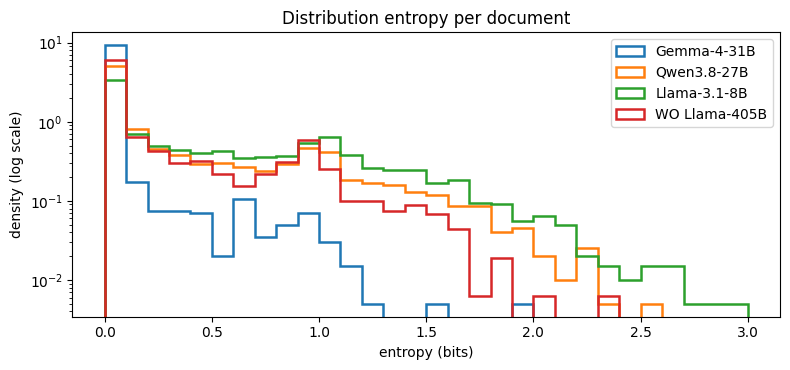

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = [i * 0.1 for i in range(31)]
series = {**runs, "WO Llama-405B": wo_405b}
for name, records in series.items():
    ax.hist([entropy_bits(r.logprobs) for r in records], bins=bins, histtype="step", linewidth=1.8, density=True, label=name)
ax.set_yscale("log")
ax.set_xlabel("entropy (bits)")
ax.set_ylabel("density (log scale)")
ax.set_title("Distribution entropy per document")
ax.legend()
fig.tight_layout()
plt.show()

## 3. What is left after the top label?

Labels are shuffled per document. If the probability left after the top label
reflected topics, the **runner-up** label's letter would be close to uniform
(1/24 = 4.2% per letter with 24 labels, 1/26 = 3.8% with 26). If a few letters dominate, the leftover probability mostly
reflects the model's preference for those letters, not a second-best topic.

- **runner-up letter chi2:** chi-square test against uniform (5% critical value 35.2).
- **top 3 runner-up letters** and their combined **share**.
- **tail spread:** the gap between the letters with the highest and lowest average
  log-probability among non-top labels, in nats. Larger means a stronger letter
  preference.

In [7]:
def runner_up_letters(records):
    """Count, per letter, how often the second most likely label was shown at it."""
    return Counter(r.letter_positions[ranked_indices(r.logprobs)[1]] for r in records)


num_letters = next(iter(runs.values()))[0].num_letters  # letters shown per document
tail_rows = []
for model, records in runs.items():
    counts = runner_up_letters(records)
    top3 = counts.most_common(3)
    # Average log-probability per letter, over all labels except each document's top label.
    leftover = {j: [] for j in range(num_letters)}
    for r in records:
        best = top_index(r.logprobs)
        for i, position in enumerate(r.letter_positions):
            if i != best:
                leftover[position].append(r.logprobs[i])
    means = [statistics.fmean(values) for values in leftover.values()]
    tail_rows.append(
        {
            "model": model,
            "runner-up letter chi2": letter_bias(records)["runner_up_chi2"],
            "top 3 runner-up letters": ", ".join(f"{LETTERS[j]} {c / n:.0%}" for j, c in top3),
            "share of top 3": sum(c for _, c in top3) / n,
            "tail spread (nats)": max(means) - min(means),
        }
    )
display(pd.DataFrame(tail_rows).round(3))

,model,runner-up letter chi2,top 3 runner-up letters,share of top 3,tail spread (nats)
0,Gemma-4-31B,4305.442,"C 23%, S 17%, B 16%",0.558,7.697
1,Qwen3.8-27B,828.228,"I 12%, A 11%, B 8%",0.304,3.043
2,Llama-3.1-8B,66.506,"S 5%, L 5%, T 5%",0.152,1.766


**Plot.** The share of documents whose runner-up label sat at each letter, one panel
per model. Bars close to the dashed line (no letter preference) mean the runner-up
reflects content; a few tall bars mean it reflects letter preferences.

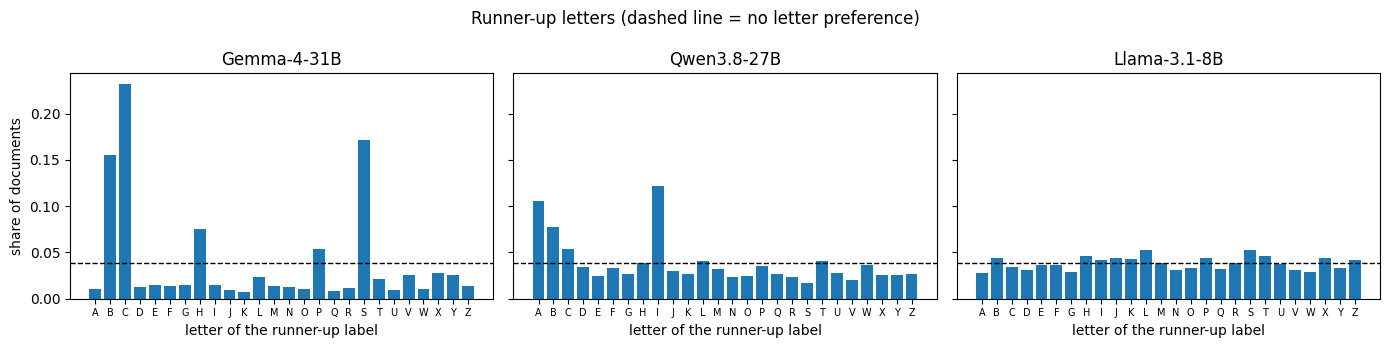

In [8]:
fig, axes = plt.subplots(1, len(runs), figsize=(14, 3.5), sharey=True)
for ax, (model, records) in zip(axes, runs.items()):
    counts = runner_up_letters(records)
    ax.bar(range(num_letters), [counts[j] / n for j in range(num_letters)])
    ax.axhline(1 / num_letters, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(range(num_letters))
    ax.set_xticklabels(list(LETTERS[:num_letters]), fontsize=7)
    ax.set_title(model)
    ax.set_xlabel("letter of the runner-up label")
axes[0].set_ylabel("share of documents")
fig.suptitle("Runner-up letters (dashed line = no letter preference)")
fig.tight_layout()
plt.show()

## 4. Agreement between models

For each pair of models:

- **top-1 agreement:** share of documents with the same top label.
- **median and mean JSD:** Jensen-Shannon divergence between the two distributions,
  0 = identical, 1 bit = no overlap. A small median with a larger mean means most
  documents agree closely and a minority differ strongly.

The cell also reports how often all models agree on the top label.

In [9]:
names = list(runs)
pair_rows = []
for a_index, a in enumerate(names):
    for b in names[a_index + 1:]:
        jsd = [jensen_shannon_bits(x.logprobs, y.logprobs) for x, y in zip(runs[a], runs[b])]
        pair_rows.append(
            {
                "pair": f"{a} vs {b}",
                "top-1 agreement": sum(top_index(x.logprobs) == top_index(y.logprobs) for x, y in zip(runs[a], runs[b])) / n,
                "median JSD (bits)": statistics.median(jsd),
                "mean JSD (bits)": statistics.fmean(jsd),
            }
        )
all_agree = sum(len({top_index(runs[m][k].logprobs) for m in names}) == 1 for k in range(n)) / n
display(pd.DataFrame(pair_rows).round(3))
print(f"All models agree on the top label for {all_agree:.1%} of documents")

,pair,top-1 agreement,median JSD (bits),mean JSD (bits)
0,Gemma-4-31B vs Qwen3.8-27B,0.859,0.006,0.118
1,Gemma-4-31B vs Llama-3.1-8B,0.675,0.079,0.289
2,Qwen3.8-27B vs Llama-3.1-8B,0.717,0.064,0.204


All models agree on the top label for 63.9% of documents


**Plot.** Top-1 agreement as a grid; brighter means more agreement. The diagonal is
each model with itself.

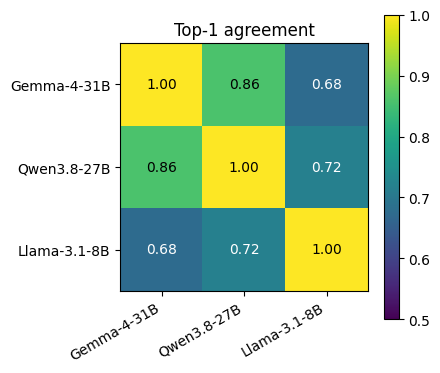

In [10]:
# Symmetric matrix of pairwise agreement, filled from pair_rows.
agreement_matrix = [[1.0 if a == b else None for b in names] for a in names]
for row in pair_rows:
    a, b = row["pair"].split(" vs ")
    agreement_matrix[names.index(a)][names.index(b)] = agreement_matrix[names.index(b)][names.index(a)] = row["top-1 agreement"]
fig, ax = plt.subplots(figsize=(4.5, 4))
image = ax.imshow(agreement_matrix, vmin=0.5, vmax=1.0, cmap="viridis")
for i in range(len(names)):
    for j in range(len(names)):
        value = agreement_matrix[i][j]
        # Dark text on the bright (high) cells, white on the dark ones.
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="black" if value >= 0.85 else "white")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.set_title("Top-1 agreement")
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

## 5. Where Qwen and Gemma disagree

On the documents where the two stronger models pick different top labels: does each
model at least give the other model's label some probability? A model whose
distributions reflect real ambiguity should give the plausible alternative a
noticeable share (here: at least 1%). A model that gives it almost nothing is
confidently one-sided even on ambiguous documents.

In [11]:
qwen, gemma = runs["Qwen3.8-27B"], runs["Gemma-4-31B"]
disagree = [(q, g) for q, g in zip(qwen, gemma) if top_index(q.logprobs) != top_index(g.logprobs)]
qwen_gives = [probabilities(q.logprobs)[top_index(g.logprobs)] for q, g in disagree]
gemma_gives = [probabilities(g.logprobs)[top_index(q.logprobs)] for q, g in disagree]
display(
    pd.DataFrame(
        [
            {
                "model": "Qwen3.8-27B",
                "median own top prob": statistics.median(top_prob(q) for q, _ in disagree),
                "gives the other's label >= 1%": sum(p >= 0.01 for p in qwen_gives) / len(disagree),
            },
            {
                "model": "Gemma-4-31B",
                "median own top prob": statistics.median(top_prob(g) for _, g in disagree),
                "gives the other's label >= 1%": sum(p >= 0.01 for p in gemma_gives) / len(disagree),
            },
        ]
    ).round(3)
)
print(f"{len(disagree)} documents with different top labels ({len(disagree) / n:.1%})")

,model,median own top prob,gives the other's label >= 1%
0,Qwen3.8-27B,0.678,0.887
1,Gemma-4-31B,1.000,0.223


282 documents with different top labels (14.1%)


**Plot.** On the disagreement documents, the probability each model gives the other
model's top label, on a log scale; the dashed line marks 1%. Mass to the right of the
line means the model keeps the alternative in play; a long tail to the far left means
it rules the alternative out.

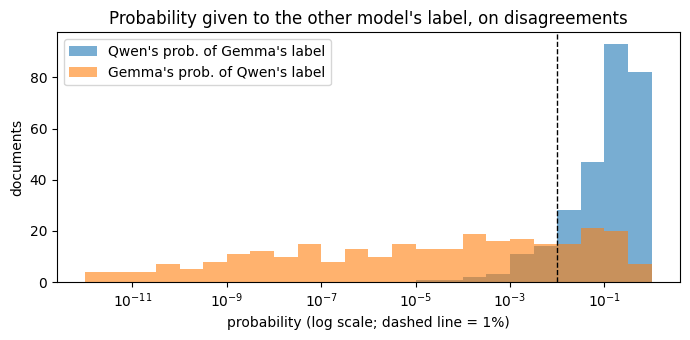

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
floor = 1e-12  # probabilities below this are drawn in the leftmost bin
log_bins = [10 ** (k / 2) for k in range(-24, 1)]
ax.hist([max(p, floor) for p in qwen_gives], bins=log_bins, alpha=0.6, label="Qwen's prob. of Gemma's label")
ax.hist([max(p, floor) for p in gemma_gives], bins=log_bins, alpha=0.6, label="Gemma's prob. of Qwen's label")
ax.axvline(0.01, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("probability (log scale; dashed line = 1%)")
ax.set_ylabel("documents")
ax.set_title("Probability given to the other model's label, on disagreements")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Summary against the report

The key numbers next to the values stated in the report. With the default
`N_DOCS = 2048` they match, apart from the report's rounding. With more documents
the values move slightly, which shows how stable the findings are. If you change
`RUNS`, rows for models that are no longer present will fail; edit the list to match.

In [13]:
by_model = {row["model"]: row for row in confidence_rows}
by_pair = {row["pair"]: row["top-1 agreement"] for row in pair_rows}
gemma_tail = next(row for row in tail_rows if row["model"] == "Gemma-4-31B")
summary = [
    ("Gemma: share >= 0.99", by_model["Gemma-4-31B"]["share >= 0.99"], 0.94),
    ("Gemma: share >= 0.999999", by_model["Gemma-4-31B"]["share >= 0.999999"], 0.78),
    ("Gemma: mean entropy (bits)", by_model["Gemma-4-31B"]["mean entropy (bits)"], 0.03),
    ("Qwen: median top prob", by_model["Qwen3.8-27B"]["median top prob"], 0.990),
    ("Qwen: share >= 0.99", by_model["Qwen3.8-27B"]["share >= 0.99"], 0.50),
    ("Qwen: mean entropy (bits)", by_model["Qwen3.8-27B"]["mean entropy (bits)"], 0.39),
    ("Llama: median top prob", by_model["Llama-3.1-8B"]["median top prob"], 0.938),
    ("Llama: mean entropy (bits)", by_model["Llama-3.1-8B"]["mean entropy (bits)"], 0.57),
    ("WO-405B: median top prob", by_model["WO Llama-405B (own documents)"]["median top prob"], 0.998),
    ("WO-405B: share >= 0.99", by_model["WO Llama-405B (own documents)"]["share >= 0.99"], 0.59),
    ("WO-405B: mean entropy (bits)", by_model["WO Llama-405B (own documents)"]["mean entropy (bits)"], 0.27),
    ("Gemma: share of top-3 runner-up letters", gemma_tail["share of top 3"], 0.58),
    ("Qwen vs Gemma agreement", by_pair["Gemma-4-31B vs Qwen3.8-27B"], 0.862),
    ("Qwen vs Llama agreement", by_pair["Qwen3.8-27B vs Llama-3.1-8B"], 0.72),
    ("all three agree", all_agree, 0.65),
    ("Qwen gives Gemma's label >= 1%", sum(p >= 0.01 for p in qwen_gives) / len(disagree), 0.93),
    ("Gemma gives Qwen's label >= 1%", sum(p >= 0.01 for p in gemma_gives) / len(disagree), 0.20),
]
display(pd.DataFrame(summary, columns=["finding", "this run", "report"]).round(3))

,finding,this run,report
0,Gemma: share >= 0.99,0.924,0.940
1,Gemma: share >= 0.999999,0.744,0.780
2,Gemma: mean entropy (bits),0.040,0.030
3,Qwen: median top prob,0.989,0.990
4,Qwen: share >= 0.99,0.488,0.500
5,Qwen: mean entropy (bits),0.383,0.390
6,Llama: median top prob,0.934,0.938
7,Llama: mean entropy (bits),0.581,0.570
8,WO-405B: median top prob,0.998,0.998
9,WO-405B: share >= 0.99,0.591,0.590
